[INFO] 1. Loading datasets...
[INFO] 2. Cleaning and standardizing datasets...
[INFO] 3. Building Fact Table...

SALES PERFORMANCE & REVENUE METRICS
Total Net Revenue    : ₱6,237,133.72
Total Realized Orders: 13,696
Unique Buyers        : 4,692
Average Order Value  : ₱455.40
One-Time Customers   : 899 (19.2%)
Repeat Customers     : 3,793 (80.8%)
[INFO] 5. Generating Visualizations...


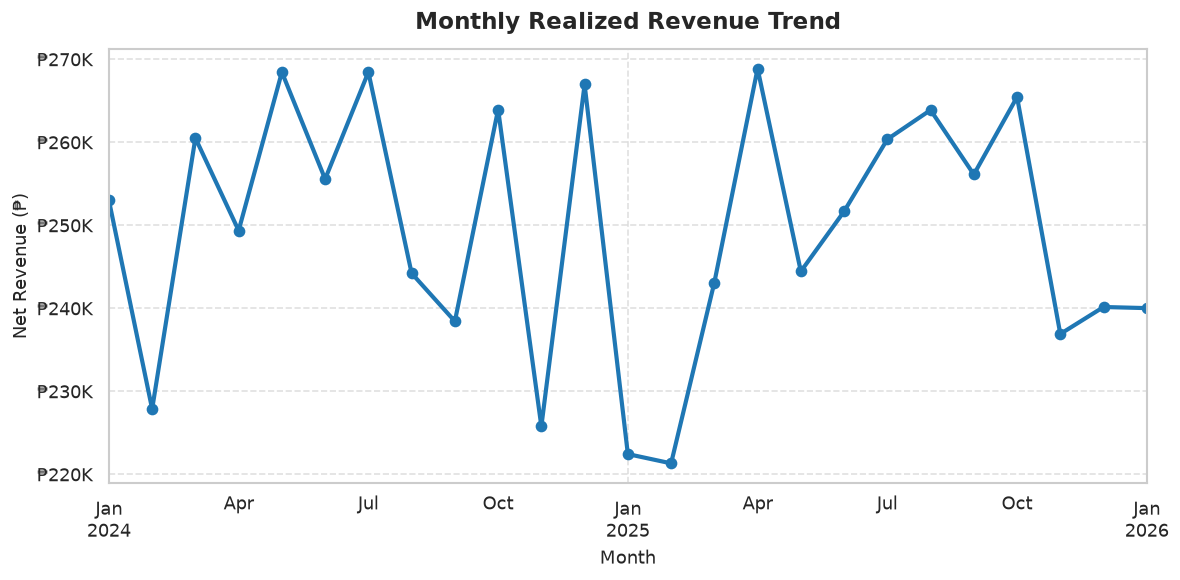

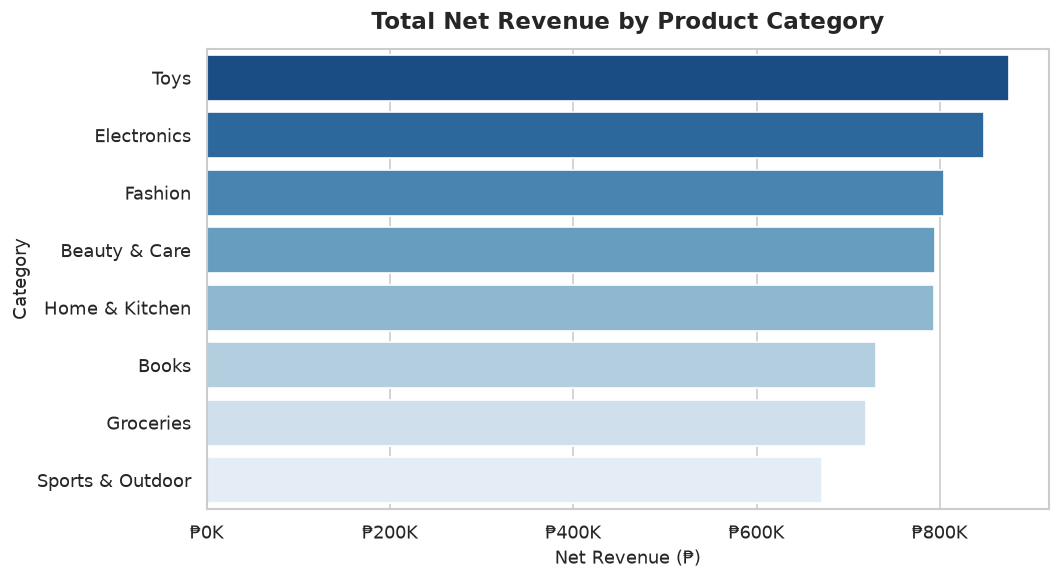

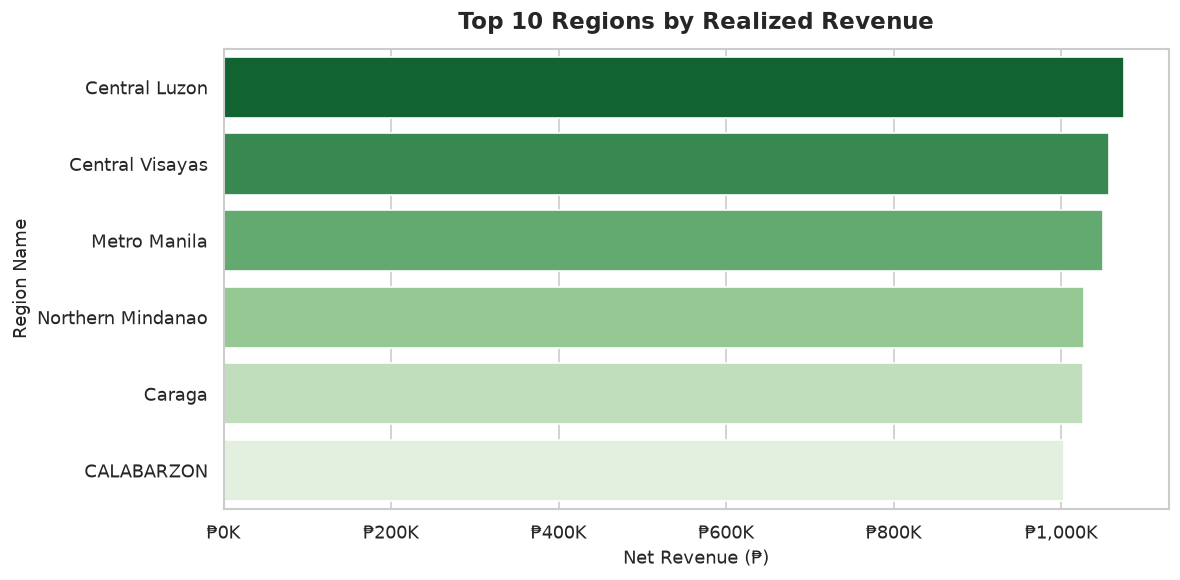

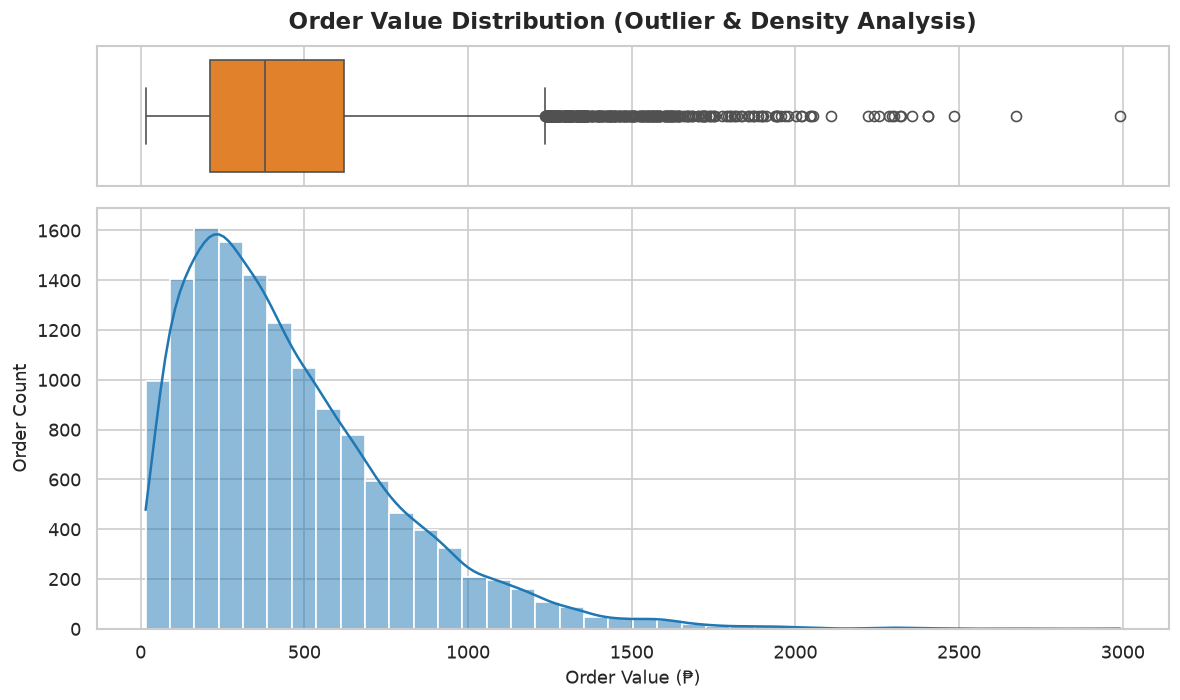

<Figure size 1200x600 with 0 Axes>

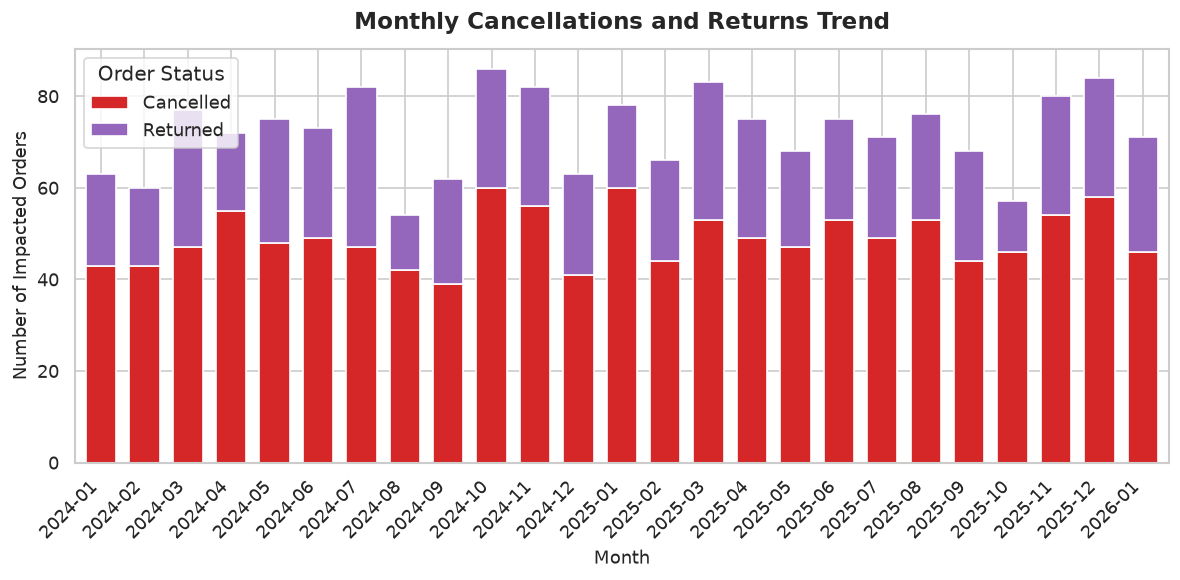

[INFO] Execution finished. All 5 charts rendered and exported as PNG files.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional presentation visuals
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

# ==============================================================================
# 1. LOAD CSV DATASETS
# ==============================================================================
print("[INFO] 1. Loading datasets...")
customers_raw = pd.read_csv("Datasets/customers.csv")
orders_raw = pd.read_csv("Datasets/orders.csv")
order_items_raw = pd.read_csv("Datasets/order_items.csv")
products_raw = pd.read_csv("Datasets/products.csv")
payments_raw = pd.read_csv("Datasets/payments.csv")
returns_raw = pd.read_csv("Datasets/returns.csv")
shipments_raw = pd.read_csv("Datasets/shipments.csv")


# ==============================================================================
# 2. DATA CLEANING & STANDARDIZATION
# ==============================================================================
print("[INFO] 2. Cleaning and standardizing datasets...")

# --- 2.1 Currency Cleaning Helper ---
def clean_currency(series: pd.Series) -> pd.Series:
    """Strips currency symbols (₱, $), commas, whitespace, and casts to float."""
    return pd.to_numeric(
        series.astype(str)
        .str.replace("₱", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce",
    )


# --- 2.2 Deduplication ---
# Definition: Records with duplicate primary business keys are redundant entries.
customers = customers_raw.drop_duplicates(subset=["customer_id"]).copy()
orders = orders_raw.drop_duplicates(subset=["order_id"]).copy()
order_items = order_items_raw.drop_duplicates(subset=["order_item_id"]).copy()
products = products_raw.drop_duplicates(subset=["product_id"]).copy()
payments = payments_raw.drop_duplicates(subset=["payment_id"]).copy()
returns = returns_raw.drop_duplicates(subset=["return_id"]).copy()
shipments = shipments_raw.drop_duplicates(subset=["shipment_id"]).copy()

# --- 2.3 Product Category Standardization ---
category_mapping = {
    "Beauty": "Beauty & Care",
    "Beauty & Care": "Beauty & Care",
    "Home and Kitchen": "Home & Kitchen",
    "Home & Kitchen": "Home & Kitchen",
    "Fashion": "Fashion",
    "Fashon": "Fashion",
    "Toys": "Toys",
    "Toy": "Toys",
    "Books": "Books",
    "Book": "Books",
    "Groceries": "Groceries",
    "Grocery": "Groceries",
    "electronics": "Electronics",
    "Electronics": "Electronics",
    "Electronics ": "Electronics",
    "Elec": "Electronics",
    "Sports": "Sports & Outdoor",
    "Sports & Outdoor": "Sports & Outdoor",
}
products["category"] = products["category"].map(category_mapping).fillna("Other")

# --- 2.4 Currency Parsing & Imputation ---
products["unit_price"] = clean_currency(products["unit_price"])
order_items["unit_price_at_purchase"] = clean_currency(order_items["unit_price_at_purchase"])
payments["amount_paid"] = clean_currency(payments["amount_paid"])
returns["refund_amount"] = clean_currency(returns["refund_amount"])

# Impute missing unit_price_at_purchase using catalog unit_price from products
order_items = order_items.merge(products[["product_id", "unit_price"]], on="product_id", how="left")
order_items["unit_price_at_purchase"] = order_items["unit_price_at_purchase"].fillna(order_items["unit_price"])
order_items.drop(columns=["unit_price"], inplace=True)

# Drop invalid / test item quantities (quantity <= 0) and unresolvable missing prices
order_items = order_items[(order_items["quantity"] > 0) & (order_items["unit_price_at_purchase"].notna())]

# --- 2.5 Handling Nulls in Orders & Customers ---
orders["discount_pct"] = orders["discount_pct"].fillna(0.0)
orders["shipping_fee"] = orders["shipping_fee"].fillna(0.0)
customers["gender"] = customers["gender"].fillna("Unknown")
customers["loyalty_tier"] = customers["loyalty_tier"].fillna("Standard")
customers["age"] = customers["age"].fillna(customers["age"].median())

# --- 2.6 Mixed Date Format Parsing ---
orders["order_datetime"] = pd.to_datetime(orders["order_datetime"], format="mixed", errors="coerce")
customers["signup_date"] = pd.to_datetime(customers["signup_date"], format="mixed", errors="coerce")
payments["payment_date"] = pd.to_datetime(payments["payment_date"], format="mixed", errors="coerce")
shipments["ship_date"] = pd.to_datetime(shipments["ship_date"], format="mixed", errors="coerce")
shipments["delivered_date"] = pd.to_datetime(shipments["delivered_date"], format="mixed", errors="coerce")
returns["return_request_date"] = pd.to_datetime(returns["return_request_date"], format="mixed", errors="coerce")

# Drop any orders where order_datetime failed parsing
orders = orders.dropna(subset=["order_datetime"])

# --- 2.7 Referential Integrity / Orphan Handling ---
valid_cust_ids = set(customers["customer_id"])
orders = orders[orders["customer_id"].isin(valid_cust_ids)]

valid_prod_ids = set(products["product_id"])
valid_active_orders = set(orders["order_id"])

# Filter order items referencing valid orders and valid products
order_items = order_items[
    (order_items["order_id"].isin(valid_active_orders)) &
    (order_items["product_id"].isin(valid_prod_ids))
]


# ==============================================================================
# 3. BUILD FACT TABLE (Orders + Items + Products + Customers)
# ==============================================================================
print("[INFO] 3. Building Fact Table...")

fact_sales = order_items.merge(
    orders, on="order_id", how="inner"
).merge(
    products, on="product_id", how="inner"
).merge(
    customers, on="customer_id", how="inner"
)

# Compute item-level gross & net revenues
fact_sales["gross_revenue"] = fact_sales["quantity"] * fact_sales["unit_price_at_purchase"]
fact_sales["net_revenue"] = fact_sales["gross_revenue"] * (1 - fact_sales["discount_pct"])
fact_sales["cogs"] = fact_sales["quantity"] * fact_sales["unit_cost"]
fact_sales["item_margin"] = fact_sales["net_revenue"] - fact_sales["cogs"]
fact_sales["order_period"] = fact_sales["order_datetime"].dt.to_period("M")
fact_sales["order_year_month"] = fact_sales["order_period"].dt.to_timestamp()
fact_sales["order_month_str"] = fact_sales["order_datetime"].dt.strftime("%Y-%m")


# ==============================================================================
# 4. COMPUTE KPIS
# ==============================================================================
print("\n" + "="*50 + "\nSALES PERFORMANCE & REVENUE METRICS\n" + "="*50)

# Standard analytical practice: Exclude Cancelled orders for actual realized revenue
realized_sales = fact_sales[fact_sales["order_status"] != "Cancelled"]

total_revenue = realized_sales["net_revenue"].sum()
total_orders = realized_sales["order_id"].nunique()
total_customers = realized_sales["customer_id"].nunique()
aov = total_revenue / total_orders if total_orders > 0 else 0

print(f"Total Net Revenue    : ₱{total_revenue:,.2f}")
print(f"Total Realized Orders: {total_orders:,}")
print(f"Unique Buyers        : {total_customers:,}")
print(f"Average Order Value  : ₱{aov:,.2f}")

# Repeat vs New Customers (Repeat = placed > 1 order)
orders_per_customer = realized_sales.groupby("customer_id")["order_id"].nunique()
new_customers = (orders_per_customer == 1).sum()
repeat_customers = (orders_per_customer > 1).sum()
repeat_rate = (repeat_customers / total_customers) * 100

print(f"One-Time Customers   : {new_customers:,} ({100 - repeat_rate:.1f}%)")
print(f"Repeat Customers     : {repeat_customers:,} ({repeat_rate:.1f}%)")

# Monthly Revenue Trend
monthly_revenue = realized_sales.groupby("order_year_month")["net_revenue"].sum()

# Top 10 Products by Revenue
top10_products = (
    realized_sales.groupby(["product_id", "product_name"])["net_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="net_revenue", ascending=False)
    .head(10)
)

# Revenue by Category
rev_by_category = (
    realized_sales.groupby("category")["net_revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Revenue by Region
rev_by_region = (
    realized_sales.groupby("region_name")["net_revenue"]
    .sum()
    .sort_values(ascending=False)
)


# ==============================================================================
# 5. VISUALIZATIONS (5 Key Business Charts)
# ==============================================================================
print("[INFO] 5. Generating Visualizations...")

# Chart 1: Monthly Revenue Trend
plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind="line", marker="o", color="#1f77b4", linewidth=2.5)
plt.title("Monthly Realized Revenue Trend", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Net Revenue (₱)", fontsize=11)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₱{x*1e-3:,.0f}K"))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("chart1_monthly_revenue_trend.png")
plt.show()

# Chart 2: Top Categories by Revenue (Fixed FutureWarning)
plt.figure(figsize=(9, 5))
sns.barplot(
    x=rev_by_category.values,
    y=rev_by_category.index,
    hue=rev_by_category.index,
    palette="Blues_r",
    legend=False,
)
plt.title("Total Net Revenue by Product Category", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Net Revenue (₱)", fontsize=11)
plt.ylabel("Category", fontsize=11)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₱{x*1e-3:,.0f}K"))
plt.tight_layout()
plt.savefig("chart2_revenue_by_category.png")
plt.show()

# Chart 3: Top 10 Revenue by Region (Fixed FutureWarning)
plt.figure(figsize=(10, 5))
top_regions = rev_by_region.head(10)
sns.barplot(
    x=top_regions.values,
    y=top_regions.index,
    hue=top_regions.index,
    palette="Greens_r",
    legend=False,
)
plt.title("Top 10 Regions by Realized Revenue", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Net Revenue (₱)", fontsize=11)
plt.ylabel("Region Name", fontsize=11)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₱{x*1e-3:,.0f}K"))
plt.tight_layout()
plt.savefig("chart3_revenue_by_region.png")
plt.show()

# Chart 4: Distribution of Order Value (AOV Outliers & Spread)
order_totals = realized_sales.groupby("order_id")["net_revenue"].sum()
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [0.25, 0.75]})
sns.boxplot(x=order_totals, ax=ax_box, color="#ff7f0e")
ax_box.set(xlabel="")
ax_box.set_title("Order Value Distribution (Outlier & Density Analysis)", fontsize=14, fontweight="bold", pad=10)
sns.histplot(order_totals, ax=ax_hist, kde=True, color="#1f77b4", bins=40)
ax_hist.set_xlabel("Order Value (₱)", fontsize=11)
ax_hist.set_ylabel("Order Count", fontsize=11)
plt.tight_layout()
plt.savefig("chart4_aov_distribution.png")
plt.show()

# Chart 5: Returns & Cancellations Monthly Trend (Clean YYYY-MM Labels)
order_exceptions = fact_sales[fact_sales["order_status"].isin(["Cancelled", "Returned"])]
exception_trend = order_exceptions.groupby(["order_month_str", "order_status"])["order_id"].nunique().unstack().fillna(0)

plt.figure(figsize=(10, 5))
exception_trend.plot(kind="bar", stacked=True, color=["#d62728", "#9467bd"], figsize=(10, 5), width=0.7)
plt.title("Monthly Cancellations and Returns Trend", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Number of Impacted Orders", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Order Status")
plt.tight_layout()
plt.savefig("chart5_cancellations_returns_trend.png")
plt.show()

print("[INFO] Execution finished. All 5 charts rendered and exported as PNG files.")